<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/03-customer-churn-prediction/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Import libraries

In [ ]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")


Libraries imported successfully.


### Cell 2 — Load the dataset
We used the IBM Telco Customer Churn dataset. The cell below attempted to load the data from a public CSV source.

In [ ]:

url = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/master/"
    "data/Telco-Customer-Churn.csv"
)

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully.")
    print("Dataset shape:", df.shape)
    display(df.head())
except Exception as error:
    print("Dataset loading failed.")
    print("Check the internet connection or dataset URL.")
    print("Error:", error)


Dataset loaded successfully.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Cell 3 - Dataset overview

In [ ]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["Churn"].value_counts())

print("\nTarget distribution (%):")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0

Target distribution:


,count
Churn,
No,5174
Yes,1869



Target distribution (%):


,proportion
Churn,
No,73.46
Yes,26.54


### Cell 4 - Clean the dataset

In [ ]:

df = df.copy()

df.columns = df.columns.str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset cleaned.")
print("Shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])


Dataset cleaned.
Shape: (7043, 21)

Missing values:


,0
TotalCharges,11


### Cell 5 — Explore class imbalance

Class counts:


,count
Churn,
No,5174
Yes,1869



Class percentages:


,proportion
Churn,
No,73.46
Yes,26.54


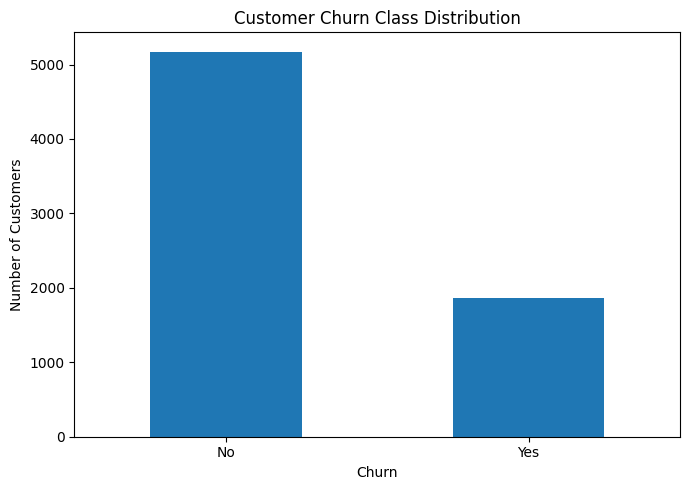

In [ ]:

churn_counts = df["Churn"].value_counts()

print("Class counts:")
display(churn_counts)

print("\nClass percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 5))
churn_counts.plot(kind="bar")
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Cell 6 — Prepare features and target
CustomerID is only a customer identifier, so we excluded it from model training. We converted Churn into a binary target: Yes = 1, No = 0

In [ ]:

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df = df.dropna(subset=["Churn"]).copy()

X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].astype(int)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Features:", X.shape[1])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Target classes:")
display(y.value_counts())


Features: 19
Numeric features: 4
Categorical features: 15
Target classes:


,count
Churn,
0,5174
1,1869


### Cell 7 - Split training and test data

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).round(3))


Training samples: 5634
Testing samples: 1409

Training class proportions:


,proportion
Churn,
0,0.735
1,0.265



Testing class proportions:


,proportion
Churn,
0,0.735
1,0.265


### Cell 8 — Build preprocessing pipeline
Missing numeric values were imputed using the median, while missing categorical values were imputed using the most frequent value. Categorical columns were one-hot encoded, and scaling was applied only to Logistic Regression.

In [ ]:

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ]
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


### Cell 9 - Define five classification models

We used balanced variants of Logistic Regression and tree-based models to compare the effects of class imbalance. This approach adjusts the class weights in the training data rather than generating synthetic samples.

In [ ]:

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        min_samples_leaf=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Five classification models defined.")


Five classification models defined.


### Cell 10 - Train models and evaluate performance

In [ ]:

trained_models = {}
predictions = {}
probabilities = {}
results = []

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
1,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
2,Random Forest,0.7828,0.5829,0.6390,0.6097,0.8336
3,Extra Trees,0.7537,0.5289,0.6604,0.5874,0.8198
4,Decision Tree,0.7303,0.4949,0.7727,0.6033,0.8004


### Cell 11 - Select the best model

Here, we considered ROC-AUC as the primary comparison metric. However, Recall and F1-score are also important for identifying customers who are likely to churn in practice.

In [ ]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by test ROC-AUC:", best_model_name)
print("Test ROC-AUC:", round(
    results_df.iloc[0]["ROC-AUC"], 4
))

print("\nBest model classification report:")
print(classification_report(
    y_test,
    predictions[best_model_name],
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Best model by test ROC-AUC: Gradient Boosting
Test ROC-AUC: 0.8434

Best model classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



Cell 12 - Compare model metrics

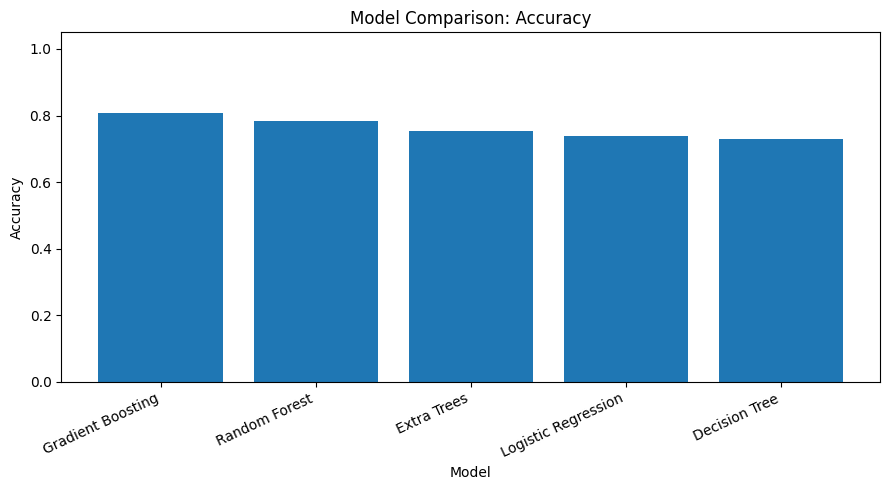

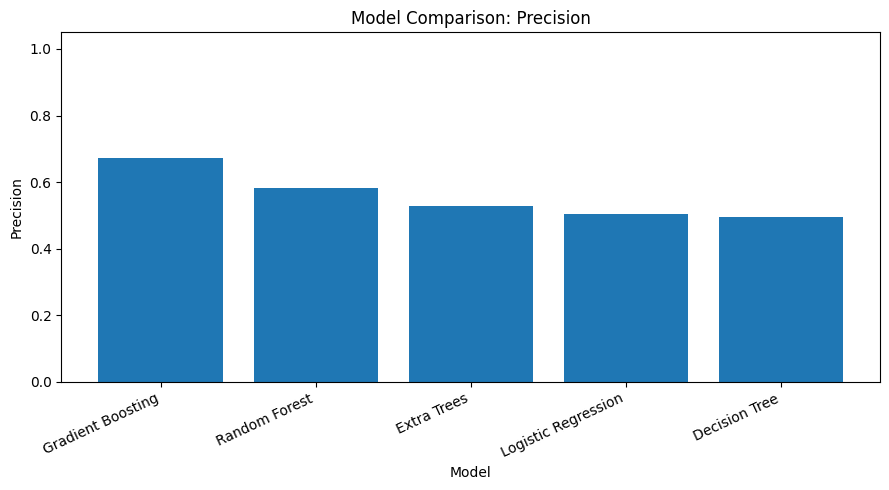

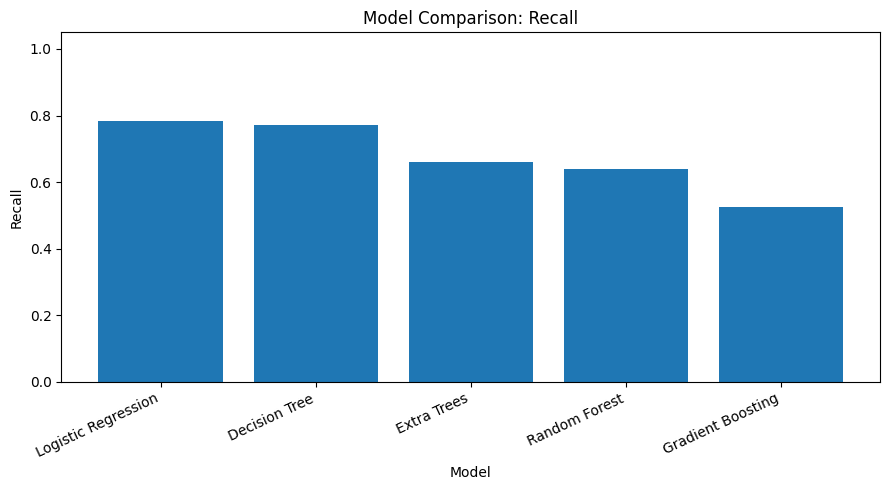

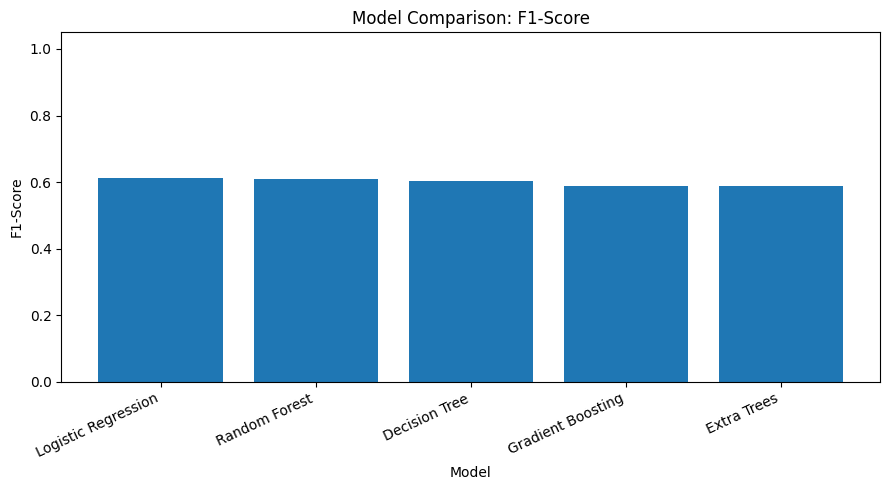

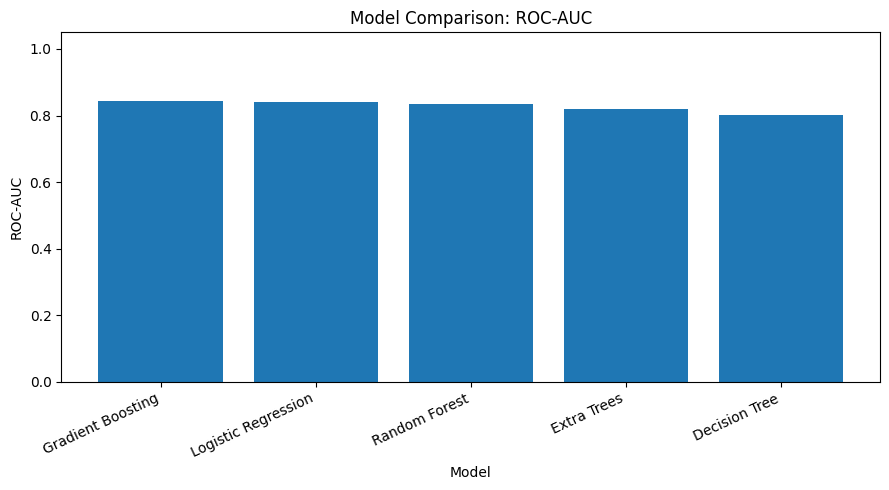

In [ ]:

metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

for metric in metrics_to_plot:
    plot_df = results_df.sort_values(
        by=metric, ascending=False
    )

    plt.figure(figsize=(9, 5))
    plt.bar(plot_df["Model"], plot_df[metric])
    plt.title(f"Model Comparison: {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


### Cell 13 - Plot ROC curves

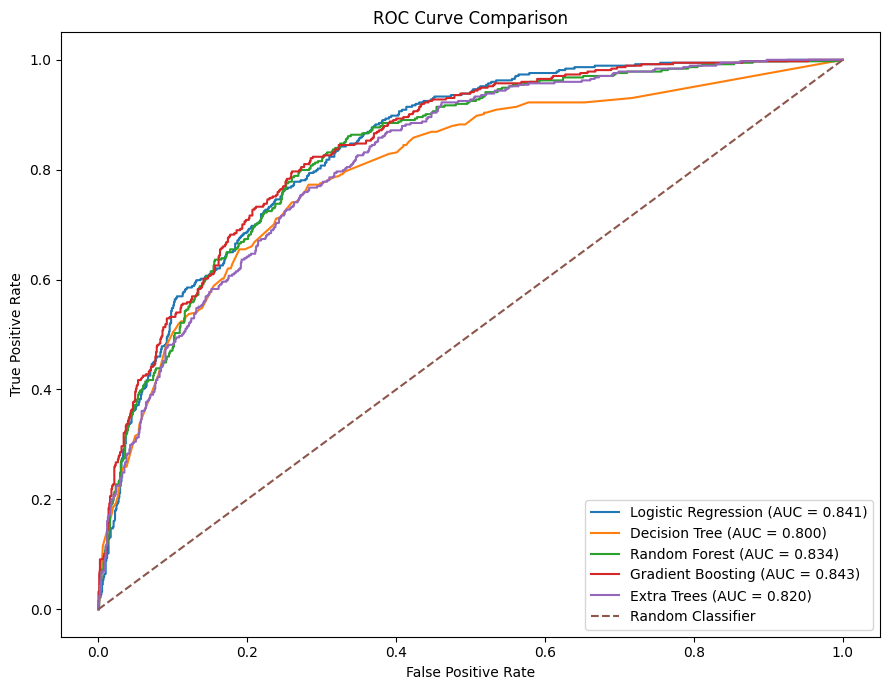

In [ ]:

plt.figure(figsize=(9, 7))

for name in models:
    fpr, tpr, _ = roc_curve(
        y_test, probabilities[name]
    )
    auc_value = roc_auc_score(
        y_test, probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Cell 14 - Best model confusion matrix

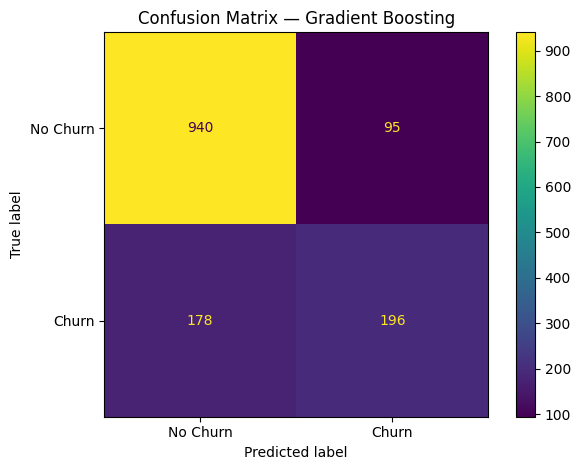

True Negatives: 940
False Positives: 95
False Negatives: 178
True Positives: 196


In [ ]:

best_predictions = predictions[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


### Cell 15 - Cross-validation on training data

We kept the test set separate. Cross-validation was performed only on the training data to prevent data leakage into the final test results.


In [ ]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy"
}

cv_results = []

for name, pipeline in trained_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "Precision Mean": scores["test_precision"].mean(),
        "Accuracy Mean": scores["test_accuracy"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="ROC-AUC Mean", ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))


,Model,ROC-AUC Mean,ROC-AUC Std,F1 Mean,Recall Mean,Precision Mean,Accuracy Mean
0,Gradient Boosting,0.8478,0.0122,0.5902,0.5338,0.6606,0.8033
1,Logistic Regression,0.8459,0.0124,0.6279,0.8013,0.5165,0.7481
2,Random Forest,0.8364,0.0093,0.6169,0.6415,0.5943,0.7886
3,Extra Trees,0.8252,0.0088,0.6137,0.6809,0.5587,0.7726
4,Decision Tree,0.7979,0.0118,0.5869,0.7538,0.4808,0.7181


### Cell 16  Feature importance using permutation importance

Permutation importance can be used with any fitted model. Here, we measured how much model performance decreases when individual features are shuffled in the test set.

,Feature,Importance Mean,Importance Std
0,Contract,0.0683,0.0028
1,tenure,0.0465,0.0021
2,MonthlyCharges,0.0126,0.0029
3,InternetService,0.0115,0.0036
4,TotalCharges,0.0109,0.0033
5,TechSupport,0.0079,0.0018
6,OnlineSecurity,0.0066,0.0009
7,MultipleLines,0.0051,0.0007
8,PaymentMethod,0.0034,0.0011
9,StreamingMovies,0.0016,0.0006


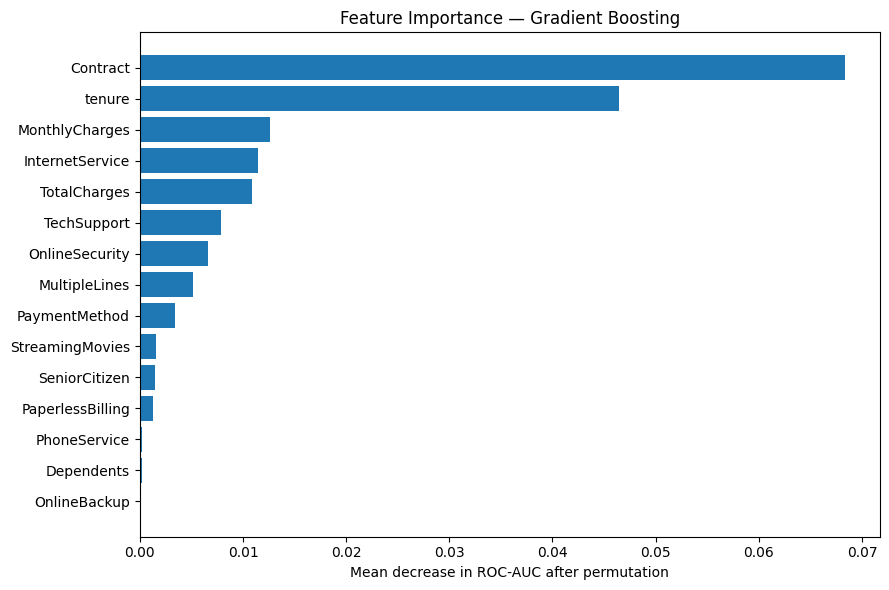

In [ ]:

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": importance_result.importances_mean,
    "Importance Std": importance_result.importances_std
}).sort_values(
    by="Importance Mean", ascending=False
).reset_index(drop=True)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values(
    by="Importance Mean"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"]
)
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.title(f"Feature Importance — {best_model_name}")
plt.tight_layout()
plt.show()


### Cell 17 - Predict churn for a sample customer

Here, we selected one customer from the test set as an example, so we can compare the prediction with the actual outcome.

In [ ]:

sample_customer = X_test.iloc[[0]]
actual_churn = int(y_test.iloc[0])

predicted_churn = int(
    best_model.predict(sample_customer)[0]
)

churn_probability = float(
    best_model.predict_proba(sample_customer)[0, 1]
)

print("Selected model:", best_model_name)
print("Actual churn:", "Yes" if actual_churn == 1 else "No")
print("Predicted churn:", "Yes" if predicted_churn == 1 else "No")
print(f"Predicted churn probability: {churn_probability:.2%}")

display(sample_customer)


Selected model: Gradient Boosting
Actual churn: No
Predicted churn: No
Predicted churn probability: 2.48%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


### Cell 18 - Save result files

In [ ]:

results_df.to_csv(
    "customer_churn_model_comparison.csv",
    index=False
)

cv_results_df.to_csv(
    "customer_churn_cross_validation.csv",
    index=False
)

importance_df.to_csv(
    "customer_churn_feature_importance.csv",
    index=False
)

print("Result files saved:")
print("- customer_churn_model_comparison.csv")
print("- customer_churn_cross_validation.csv")
print("- customer_churn_feature_importance.csv")


Result files saved:
- customer_churn_model_comparison.csv
- customer_churn_cross_validation.csv
- customer_churn_feature_importance.csv


### Cell 19 - Generate results-based analysis

This cell generates a summary based on the actual results, without using any hardcoded scores

In [ ]:

best_auc_row = results_df.loc[results_df["ROC-AUC"].idxmax()]
best_f1_row = results_df.loc[results_df["F1-Score"].idxmax()]
best_recall_row = results_df.loc[results_df["Recall"].idxmax()]

best_cv_row = cv_results_df.loc[
    cv_results_df["ROC-AUC Mean"].idxmax()
]

print("=" * 60)
print("CUSTOMER CHURN PREDICTION — RESULTS ANALYSIS")
print("=" * 60)

print(f"\nBest model by test ROC-AUC: {best_auc_row['Model']}")
print(f"Test ROC-AUC: {best_auc_row['ROC-AUC']:.4f}")

print(f"\nBest model by F1-score: {best_f1_row['Model']}")
print(f"F1-score: {best_f1_row['F1-Score']:.4f}")

print(f"\nBest model by Recall: {best_recall_row['Model']}")
print(f"Recall: {best_recall_row['Recall']:.4f}")

print(f"\nBest model by CV ROC-AUC: {best_cv_row['Model']}")
print(f"CV ROC-AUC mean: {best_cv_row['ROC-AUC Mean']:.4f}")
print(f"CV ROC-AUC std: {best_cv_row['ROC-AUC Std']:.4f}")

print("\nClass distribution:")
display(
    pd.DataFrame({
        "Count": y.value_counts(),
        "Percentage": (y.value_counts(normalize=True) * 100).round(2)
    })
)

print("\nTop 10 features by permutation importance:")
display(importance_df.head(10).round(4))

print("\nFull test-set comparison:")
display(results_df.round(4))

print("\nCross-validation comparison:")
display(cv_results_df.round(4))


CUSTOMER CHURN PREDICTION — RESULTS ANALYSIS

Best model by test ROC-AUC: Gradient Boosting
Test ROC-AUC: 0.8434

Best model by F1-score: Logistic Regression
F1-score: 0.6136

Best model by Recall: Logistic Regression
Recall: 0.7834

Best model by CV ROC-AUC: Gradient Boosting
CV ROC-AUC mean: 0.8478
CV ROC-AUC std: 0.0122

Class distribution:


,Count,Percentage
Churn,,
0,5174,73.46
1,1869,26.54



Top 10 features by permutation importance:


,Feature,Importance Mean,Importance Std
0,Contract,0.0683,0.0028
1,tenure,0.0465,0.0021
2,MonthlyCharges,0.0126,0.0029
3,InternetService,0.0115,0.0036
4,TotalCharges,0.0109,0.0033
5,TechSupport,0.0079,0.0018
6,OnlineSecurity,0.0066,0.0009
7,MultipleLines,0.0051,0.0007
8,PaymentMethod,0.0034,0.0011
9,StreamingMovies,0.0016,0.0006



Full test-set comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
1,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
2,Random Forest,0.7828,0.5829,0.6390,0.6097,0.8336
3,Extra Trees,0.7537,0.5289,0.6604,0.5874,0.8198
4,Decision Tree,0.7303,0.4949,0.7727,0.6033,0.8004



Cross-validation comparison:


,Model,ROC-AUC Mean,ROC-AUC Std,F1 Mean,Recall Mean,Precision Mean,Accuracy Mean
0,Gradient Boosting,0.8478,0.0122,0.5902,0.5338,0.6606,0.8033
1,Logistic Regression,0.8459,0.0124,0.6279,0.8013,0.5165,0.7481
2,Random Forest,0.8364,0.0093,0.6169,0.6415,0.5943,0.7886
3,Extra Trees,0.8252,0.0088,0.6137,0.6809,0.5587,0.7726
4,Decision Tree,0.7979,0.0118,0.5869,0.7538,0.4808,0.7181


### Cell 20 - Create a concise project summary

In [ ]:

summary = f"""
Project: Customer Churn Prediction Using Machine Learning

Dataset rows after cleaning: {len(df)}
Number of features: {X.shape[1]}
Training samples: {len(X_train)}
Testing samples: {len(X_test)}

Best model by test ROC-AUC: {best_auc_row['Model']}
Test ROC-AUC: {best_auc_row['ROC-AUC']:.4f}
Test F1-score: {best_auc_row['F1-Score']:.4f}
Test Recall: {best_auc_row['Recall']:.4f}
Test Precision: {best_auc_row['Precision']:.4f}
Test Accuracy: {best_auc_row['Accuracy']:.4f}

Best model by training cross-validation ROC-AUC:
{best_cv_row['Model']}

Mean CV ROC-AUC: {best_cv_row['ROC-AUC Mean']:.4f}
CV ROC-AUC standard deviation: {best_cv_row['ROC-AUC Std']:.4f}

The model comparison includes five classifiers.
Evaluation includes accuracy, precision, recall, F1-score,
ROC-AUC, ROC curves, confusion matrix and cross-validation.
"""

print(summary)

with open("customer_churn_results_summary.txt", "w") as file:
    file.write(summary)

print("\nSummary saved to customer_churn_results_summary.txt")



Project: Customer Churn Prediction Using Machine Learning

Dataset rows after cleaning: 7043
Number of features: 19
Training samples: 5634
Testing samples: 1409

Best model by test ROC-AUC: Gradient Boosting
Test ROC-AUC: 0.8434
Test F1-score: 0.5895
Test Recall: 0.5241
Test Precision: 0.6735
Test Accuracy: 0.8062

Best model by training cross-validation ROC-AUC:
Gradient Boosting

Mean CV ROC-AUC: 0.8478
CV ROC-AUC standard deviation: 0.0122

The model comparison includes five classifiers.
Evaluation includes accuracy, precision, recall, F1-score,
ROC-AUC, ROC curves, confusion matrix and cross-validation.


Summary saved to customer_churn_results_summary.txt


### Cell 21 - Download the summary

In [ ]:
from google.colab import files
files.download("customer_churn_results_summary.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Cell 23 - Generate a GitHub-ready README

In [ ]:

results_table = results_df.round(4).to_markdown(index=False)
cv_table = cv_results_df.round(4).to_markdown(index=False)
features_table = importance_df.head(10).round(4).to_markdown(index=False)

readme = f"""# Customer Churn Prediction Using Machine Learning

## Overview

This project predicts whether a customer is likely to leave a service
using supervised machine learning classification algorithms.

The project focuses on class imbalance, model comparison, ROC-AUC,
cross-validation, and identifying important customer features.

## Objectives

- Build and compare five classification models.
- Evaluate class imbalance in the target variable.
- Compare Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Visualize ROC curves and confusion matrices.
- Evaluate model stability using stratified 5-fold cross-validation.
- Explore feature importance using permutation importance.

## Dataset

The project uses the Telco Customer Churn dataset.

The target variable is `Churn`:
- `Yes` = 1
- `No` = 0

The `customerID` column is excluded from model training.

## Models

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. Extra Trees

Balanced class weights are used for Logistic Regression, Decision Tree,
Random Forest, and Extra Trees. Gradient Boosting is included as a
comparison model without class-weight adjustment.

## Methodology

1. Load and inspect the dataset.
2. Clean numeric values and inspect missing data.
3. Analyze the churn class distribution.
4. Split data into training and test sets using stratification.
5. Impute missing values, scale numeric features, and one-hot encode
   categorical features using a preprocessing pipeline.
6. Train five classification models.
7. Evaluate models on the held-out test set.
8. Run stratified 5-fold cross-validation on training data.
9. Compare ROC curves, confusion matrices, and feature importance.

## Test Set Results

{results_table}

## Cross-Validation Results

{cv_table}

## Top Features by Permutation Importance

{features_table}

## Best Model

Best model by test ROC-AUC: **{best_auc_row['Model']}**

- ROC-AUC: {best_auc_row['ROC-AUC']:.4f}
- Accuracy: {best_auc_row['Accuracy']:.4f}
- Precision: {best_auc_row['Precision']:.4f}
- Recall: {best_auc_row['Recall']:.4f}
- F1-score: {best_auc_row['F1-Score']:.4f}

The best model may differ depending on the metric. ROC-AUC is used as
the primary ranking metric in this project, while Recall and F1-score
are also important for churn detection.

## Limitations

- Results depend on the selected dataset and its quality.
- Class weighting does not guarantee that every minority-class metric
  will improve.
- The selected classification threshold may not be optimal for every
  business use case.
- Feature importance indicates predictive association, not causation.
- Results on this dataset do not guarantee performance on new customers
  or other companies.

## Future Improvements

- Tune classification thresholds using validation data.
- Compare class weighting with resampling methods such as SMOTE,
  applied only within training folds.
- Perform hyperparameter optimization.
- Evaluate business costs of false positives and false negatives.
- Deploy a simple customer churn prediction interface.

## Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Scikit-learn, Google Colab, GitHub.

## Reproducibility

The experiment uses a fixed random seed of 42 for reproducibility.
Model performance is reported from the held-out test set, while
cross-validation is conducted on the training set.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md generated using actual results.")
files.download("README.md")


README.md generated using actual results.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>